# Hierarchical Clustering

In [2]:
%pip install "numpy<2" --force-reinstall

import pandas as pd
import numpy as np

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "df_prepared.csv"  # <-- adjust if needed
df = pd.read_csv(DATA_PATH)

ID_COL = "BGGId"
TARGET_COL = "Rating"

CAT_COLS = [
    "Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
    "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"
]
BINARY_EXTRA = ["IsReimplementation", "Kickstarted"]
BINARY_COLS = CAT_COLS + BINARY_EXTRA

print("=== Loaded dataset ===")
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))

print("\n=== Quick sanity checks ===")

required = [ID_COL, TARGET_COL] + BINARY_COLS
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")
print("Required columns present")

na_counts = df.isna().sum().sort_values(ascending=False)
print("\nTop missing-value columns (if any):")
print(na_counts.head(10))

print("\nBinary column value check (unique values):")
binary_ok = True
for c in BINARY_COLS:
    uniq = sorted(df[c].dropna().unique().tolist())
    ok = set(uniq).issubset({0, 1})
    binary_ok = binary_ok and ok
    print(f"  {c:<18} uniques={uniq}  -> {'OK' if ok else 'NOT OK'}")
if not binary_ok:
    raise ValueError("Some binary columns contain values outside {0,1}.")

print("\nBinary columns look valid")

dup_ids = df.duplicated(subset=[ID_COL]).sum()
print(f"\nDuplicate {ID_COL} rows:", dup_ids)

print("\nTarget (Rating) distribution:")
print(df[TARGET_COL].value_counts(dropna=False))

print("\nDataset is loaded and passes basic sanity checks")

  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.
=== Loaded dataset ===
Shape: (20573, 30)

Columns: ['BGGId', 'GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy', 'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party', 'Cat:Childrens', 'Rating', 'Age', 'AvgPlaytime', 'AgeRec', 'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log', 'MaxPlayers_log']

=== Quick sanity checks ===
Required columns present

Top missing-value columns (if any):
BGGId                     0
GameWeight         

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.24.0 requires numpy>=2.3.5, but you have numpy 1.26.4 which is incompatible.


## Feature selection for hierarchical clustering

Hierarchical clustering relies on a distance metric defined in a feature space. Since we use **Ward linkage with Euclidean distance**, the clustering variables must be continuous and comparable under Euclidean geometry. For this reason, we explicitly distinguish between:

1. **Features used to compute the clustering**, and  
2. **Features used only for interpretation after clustering**.

---

### Features used for clustering (continuous)

We define the following six continuous variables as the clustering space:

- **GameWeight** — proxy for game complexity.
- **MinPlayers** — minimum number of players required.
- **MaxPlayers_log** — upper bound on player count (log-transformed to reduce skew).
- **Age** — years since publication.
- **AvgPlaytime_log** — typical session duration (log-transformed).
- **AgeRec** — recommended player age.

These attributes describe *gameplay structure and design intent*, such as complexity, duration, audience, and group size. They are directly comparable across games and meaningful for similarity-based grouping.

#### Why include *MinPlayers*?
While `MaxPlayers` captures how large a group a game can support, it does not distinguish games that require exactly two players from those playable across a wide range. Including `MinPlayers` allows the clustering to capture **constraints on the lower bound of group size**, which is a key aspect of gameplay design and helps separate, for example, strictly two-player games from flexible party or family games.

---

### Features excluded from clustering (used only for interpretation)

The following variables are intentionally excluded from distance computation:

- **Category flags** (e.g., Strategy, War, Party, Family)
- **Kickstarter / Reimplementation indicators**
- **Popularity and engagement counts** (e.g., number of owners, expansions, alternates)

These variables are binary or highly skewed, and including them directly in a Euclidean space would distort distances or require arbitrary weighting.

Instead, they are used *after clustering* to interpret and label the resulting groups. This separation ensures that cluster formation is driven by

In [3]:
# ============================================================
# 2) Feature set definition for hierarchical clustering
# ============================================================

# Continuous features used to COMPUTE distances
# (gameplay / design descriptors only)
CLUSTER_FEATURES = [
    "GameWeight",        # complexity
    "MinPlayers",        # minimum viable group size
    "MaxPlayers_log",    # upper bound on players (log-transformed)
    "Age",               # publication age
    "AvgPlaytime_log",   # typical session duration (log-transformed)
    "AgeRec"             # recommended player age
]

# Features used ONLY for interpretation (not for clustering)
INTERPRET_CONTINUOUS = [
    "NumOwned",
    "NumWant",
    "NumAlternates",
    "NumExpansions",
    "NumImplementations"
]

INTERPRET_BINARY = [
    "Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
    "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens",
    "IsReimplementation", "Kickstarted"
]

print("=== Clustering features (used to compute distances) ===")
for f in CLUSTER_FEATURES:
    print(" -", f)

print("\n=== Interpretation-only continuous features ===")
for f in INTERPRET_CONTINUOUS:
    print(" -", f)

print("\n=== Interpretation-only binary features ===")
for f in INTERPRET_BINARY:
    print(" -", f)

=== Clustering features (used to compute distances) ===
 - GameWeight
 - MinPlayers
 - MaxPlayers_log
 - Age
 - AvgPlaytime_log
 - AgeRec

=== Interpretation-only continuous features ===
 - NumOwned
 - NumWant
 - NumAlternates
 - NumExpansions
 - NumImplementations

=== Interpretation-only binary features ===
 - Cat:Thematic
 - Cat:Strategy
 - Cat:War
 - Cat:Family
 - Cat:CGS
 - Cat:Abstract
 - Cat:Party
 - Cat:Childrens
 - IsReimplementation
 - Kickstarted


In [4]:
# ============================================================
# 3) Build matrices: raw vs X for clustering + scaling validation
# ============================================================

from sklearn.preprocessing import StandardScaler

# Keep an untouched copy for interpretation later
df_raw = df.copy()

# Build clustering matrix (continuous features only)
X = df_raw[CLUSTER_FEATURES].copy()

# Safety checks before scaling
if X.isna().any().any():
    raise ValueError("NaNs found in clustering features. Fix missing values before scaling.")
if np.isinf(X.to_numpy()).any():
    raise ValueError("Inf values found in clustering features. Fix infinities before scaling.")

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Wrap back into a DataFrame for readability
X_scaled = pd.DataFrame(X_scaled, columns=CLUSTER_FEATURES, index=df_raw.index)

print("=== Matrices created ===")
print("df_raw shape (interpretation space):", df_raw.shape)
print("X shape (clustering space, unscaled):", X.shape)
print("X_scaled shape (clustering space, scaled):", X_scaled.shape)

# Quick validation: scaled means and stds should be ~0 and ~1
scale_check = pd.DataFrame({
    "mean": X_scaled.mean().round(3),
    "std":  X_scaled.std(ddof=0).round(3)  # ddof=0 matches StandardScaler definition
})

print("\n=== Scaling validation (should be ~0 mean and ~1 std) ===")
display(scale_check)

=== Matrices created ===
df_raw shape (interpretation space): (20573, 30)
X shape (clustering space, unscaled): (20573, 6)
X_scaled shape (clustering space, scaled): (20573, 6)

=== Scaling validation (should be ~0 mean and ~1 std) ===


,mean,std
GameWeight,0.0,1.0
MinPlayers,-0.0,1.0
MaxPlayers_log,0.0,1.0
Age,0.0,1.0
AvgPlaytime_log,-0.0,1.0
AgeRec,-0.0,1.0


## Building the clustering matrix and standardization (results)

We created two separate data objects:

- **`df_raw`** (shape: **20,573 × 30**) — the full prepared dataset used later for **interpretation** (category flags, popularity indicators, metadata).
- **`X`** (shape: **20,573 × 6**) — the continuous feature subset used to compute distances for hierarchical clustering:
  - `GameWeight`, `MinPlayers`, `MaxPlayers_log`, `Age`, `AvgPlaytime_log`, `AgeRec`.

### Why standardization is necessary
Hierarchical clustering with Ward linkage relies on **Euclidean distances**. Euclidean distance is scale-sensitive: without normalization, variables with larger numeric ranges (e.g., `Age`) would dominate the distance computation and therefore dominate cluster merges, even if they are not semantically more important.

We therefore standardize all clustering features with **z-score normalization**:

\[
z = \frac{x - \mu}{\sigma}
\]

### Scaling validation
After applying `StandardScaler`, the resulting matrix **`X_scaled`** has:
- mean approximately **0**
- standard deviation approximately **1**

for all six features (as shown in the validation table). This confirms that all variables contribute comparably to the Euclidean distance used by Ward linkage.


In [5]:
# ============================================================
# 4) Sampling strategy for dendrogram visualization
# ============================================================

SAMPLE_SIZE = 3000  # change to 2000 if linkage becomes slow/heavy

# Sample indices from the full dataset (reproducible)
sample_idx = df_raw.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).index

# Subset both spaces consistently
df_sample_raw = df_raw.loc[sample_idx].copy()       # interpretation space
X_sample = X.loc[sample_idx].copy()                 # unscaled clustering space (optional, for readable stats)
X_sample_scaled = X_scaled.loc[sample_idx].copy()   # scaled clustering space (used for linkage)

print("=== Sample created for dendrogram visualization ===")
print("Sample size:", SAMPLE_SIZE)
print("df_sample_raw shape:", df_sample_raw.shape)
print("X_sample_scaled shape:", X_sample_scaled.shape)

# Optional quick check: ensure alignment
assert df_sample_raw.index.equals(X_sample_scaled.index), "Index mismatch between raw sample and scaled sample!"
print("Index alignment check ✅")

=== Sample created for dendrogram visualization ===
Sample size: 3000
df_sample_raw shape: (3000, 30)
X_sample_scaled shape: (3000, 6)
Index alignment check ✅


## Sampling for dendrogram computation and readability

Hierarchical clustering linkage computation requires evaluating pairwise distances between points, which has **quadratic complexity** in the number of observations (approximately \(O(n^2)\) in memory/time for distance-based linkage). With more than 20k games, computing and plotting a full dendrogram becomes both computationally expensive and visually unreadable.

For this reason, we construct dendrograms using a **random sample of 3,000 games**, drawn with a fixed random seed for reproducibility.

### Important note on interpretation
- Sampling is used **only for dendrogram visualization and linkage comparison**.
- The clustering feature space remains unchanged (standardized continuous variables).
- Cluster interpretation is later performed using the corresponding raw sample (`df_sample_raw`) to compute medians and category prevalences.

This approach preserves methodological correctness while producing dendrograms that are tractable and interpretable.

In [6]:
# ============================================================
# 5) Compute linkage matrices (multiple linkage strategies)
# ============================================================

from scipy.cluster.hierarchy import linkage

# Dictionary to store linkage matrices
linkage_matrices = {}

# Linkage methods to compare
linkage_methods = ["ward", "complete", "average"]

for method in linkage_methods:
    if method == "ward":
        Z = linkage(X_sample_scaled, method="ward", metric="euclidean")
    else:
        Z = linkage(X_sample_scaled, method=method, metric="euclidean")
    
    linkage_matrices[method] = Z
    print(f"Linkage computed: {method} | shape = {Z.shape}")

print("\nAvailable linkage matrices:", list(linkage_matrices.keys()))

Linkage computed: ward | shape = (2999, 4)
Linkage computed: complete | shape = (2999, 4)
Linkage computed: average | shape = (2999, 4)

Available linkage matrices: ['ward', 'complete', 'average']


Hierarchical clustering builds a tree of nested clusters by iteratively merging the most similar groups. The notion of “similarity” depends on the **linkage criterion**, which defines how the distance between two clusters is computed.

To analyze the robustness of the hierarchical structure, we compute several linkage matrices using the same standardized feature space:

### Linkage methods considered

- **Ward linkage**
  - Merges clusters that minimize the increase in within-cluster variance.
  - Produces compact, spherical clusters.
  - Closely related to the objective optimized by k-means.
  - Particularly suitable when clustering continuous standardized features.

- **Complete linkage**
  - Defines distance between clusters as the *maximum* pairwise distance.
  - Tends to form tight, compact clusters.
  - More sensitive to outliers than Ward.

- **Average linkage**
  - Uses the average pairwise distance between clusters.
  - Represents a compromise between single-link (chaining) and complete-link behavior.
  - Often produces more balanced hierarchies.

All linkage methods are computed using **Euclidean distance** on the standardized feature space, ensuring comparability.

### Why compare multiple linkages?
Different linkage strategies can produce different hierarchical structures even on the same data. By examining several dendrograms, we can:

- assess the stability of major cluster separations,
- identify consistent high-level splits,
- select a linkage method that balances compactness and interpretability.

In the next step, dendrograms corresponding to these linkage matrices are visualized and compared.

## Linkage matrices computed (results)

We computed hierarchical linkage matrices on the standardized feature space `X_sample_scaled` for three linkage criteria:

- **Ward** linkage  
- **Complete** linkage  
- **Average** linkage  

Since the dendrogram for a dataset of size \(n\) contains exactly \(n-1\) merge operations, each linkage matrix has shape \((3000-1, 4) = (2999, 4)\), which matches our output for all three strategies.

These linkage matrices will be used in the next step to visualize and compare dendrogram structures, with the goal of identifying stable merge patterns and selecting an interpretable cut level.


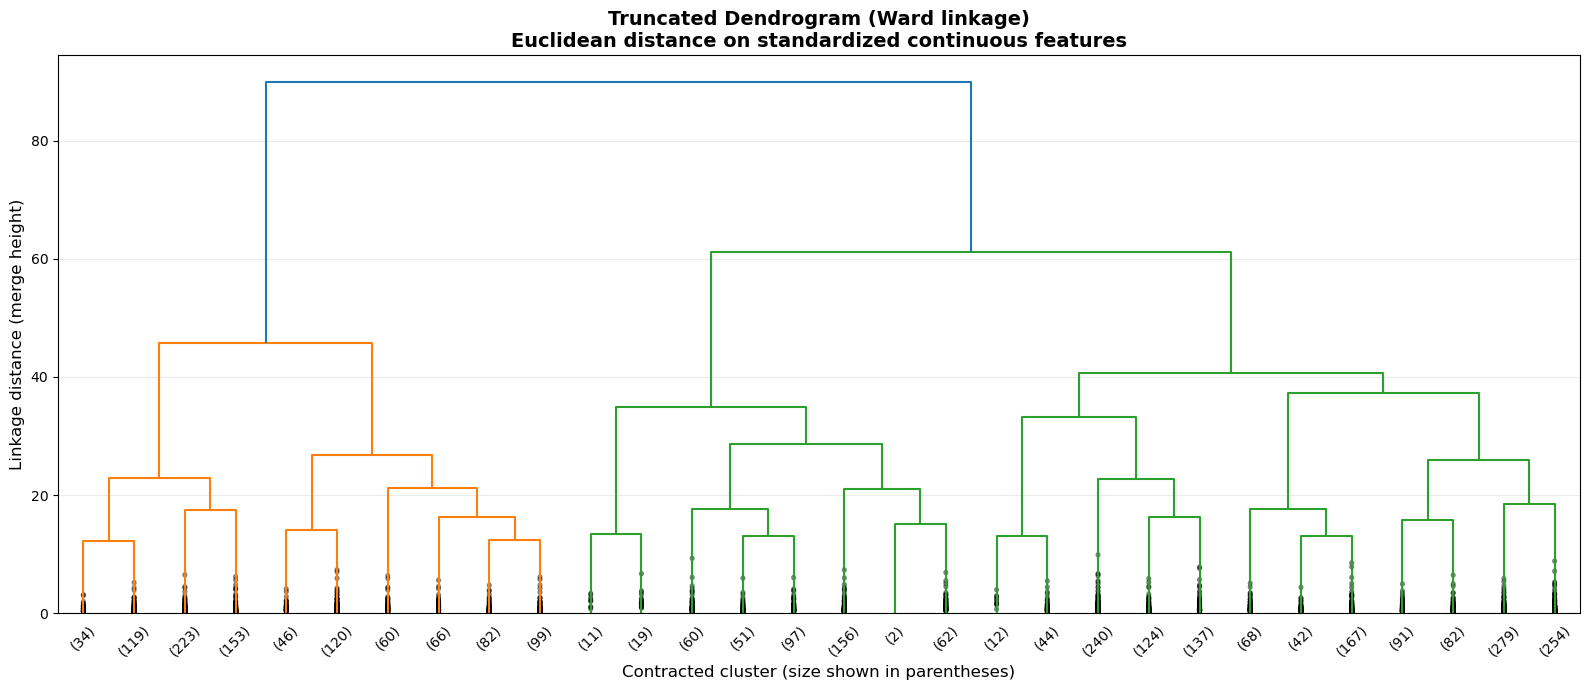

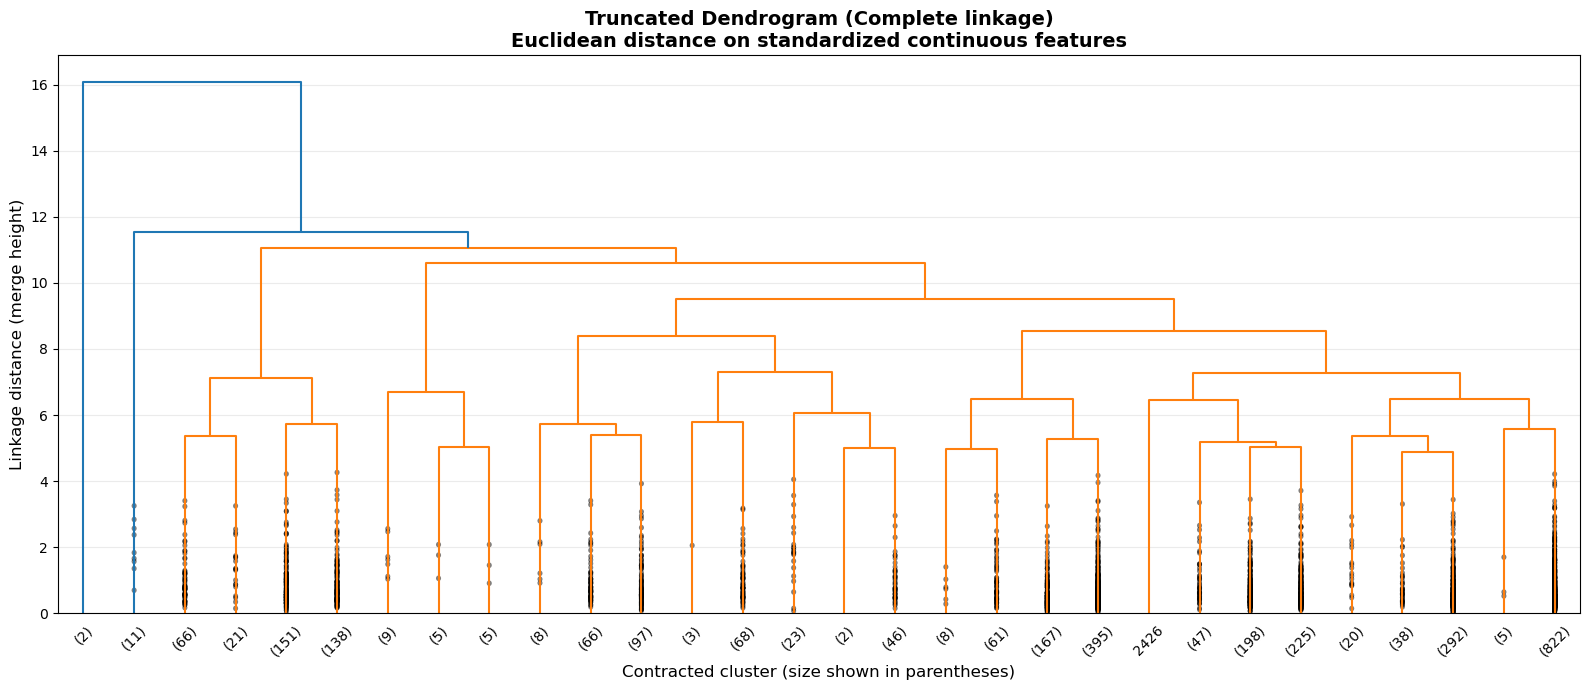

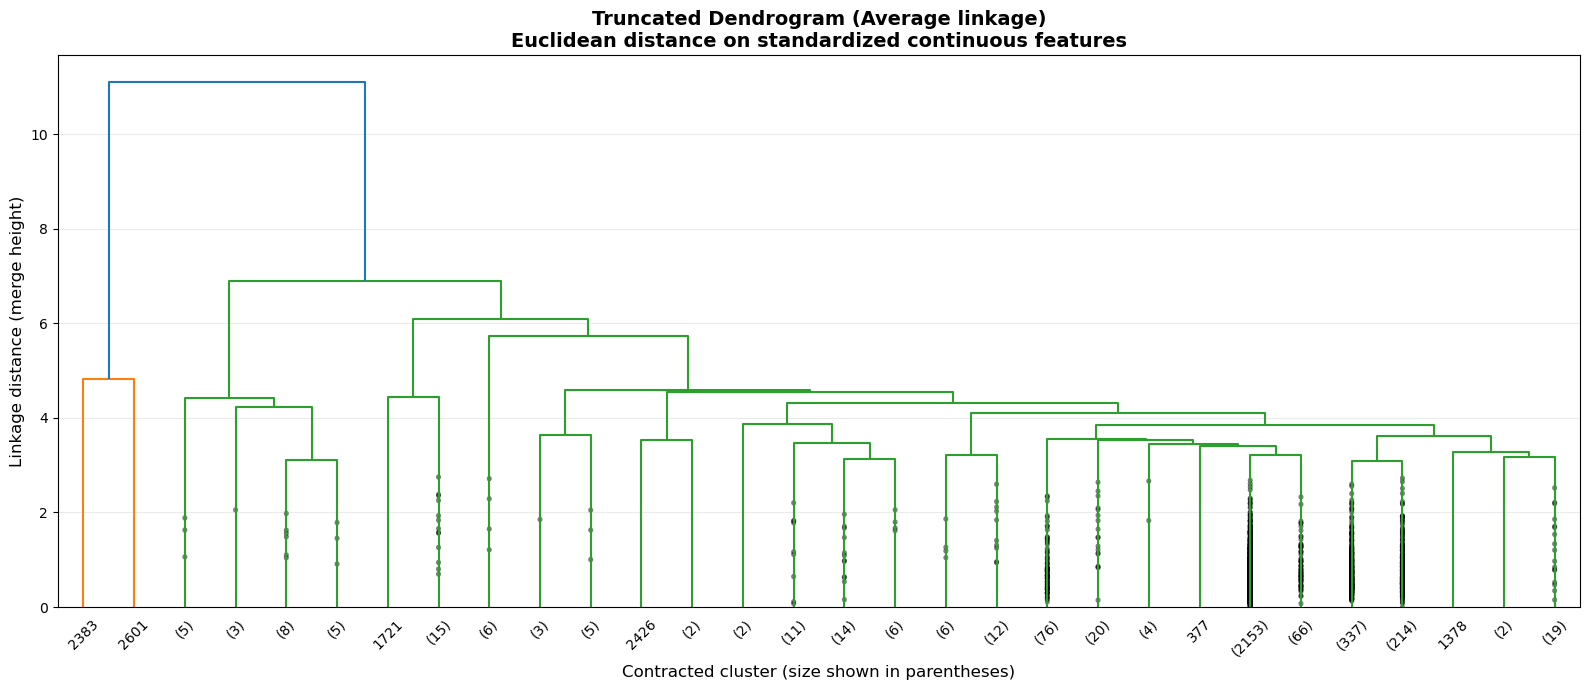

In [7]:
# ============================================================
# 6) Plot dendrograms (truncated) for each linkage
# ============================================================

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

# Dendrogram plotting settings (keep consistent across linkages)
DENDRO_P = 30          # number of contracted leaves shown
FIGSIZE = (16, 7)      # consistent size

for method, Z in linkage_matrices.items():
    plt.figure(figsize=FIGSIZE)
    
    dendrogram(
        Z,
        truncate_mode="lastp",
        p=DENDRO_P,
        show_contracted=True,
        leaf_font_size=10,
    )
    
    plt.title(
        f"Truncated Dendrogram ({method.capitalize()} linkage)\n"
        f"Euclidean distance on standardized continuous features",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel("Contracted cluster (size shown in parentheses)", fontsize=12)
    plt.ylabel("Linkage distance (merge height)", fontsize=12)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


## Dendrogram comparison across linkage methods (interpretation guide)

We plot **truncated dendrograms** for Ward, Complete, and Average linkage using the same settings (same sample, same standardized feature space, same truncation parameter `p`). Truncation aggregates many individual games into contracted leaves, so the dendrogram is intended for **macro-structure inspection**, not for exact point-level conclusions.

### Important note about colors
Dendrogram colors are **qualitative** in this visualization. Because we truncate the tree (show only the last `p` contracted leaves), colors should not be interpreted as exact final clusters. The key information for selecting a cut level is instead the **merge heights** (the y-axis distances), i.e., where large vertical gaps appear.

### How to read the dendrogram
- The **y-axis** shows the distance at which merges occur.
- **Large merge heights** (big jumps) indicate that two relatively dissimilar groups were merged; these are candidate levels for cutting the dendrogram.
- If merge heights increase gradually with no large gaps, the data may not have sharply separated cluster structure under that linkage.

### What we compare across linkages
We compare:
- whether there are clear “jump” regions (macro separations),
- whether the hierarchy looks stable or overly fragmented,
- whether merges appear balanced or dominated by chaining (unwanted for interpretability).

### Linkage selection
After comparing the dendrograms, we select a linkage criterion to proceed with final cluster extraction.  
In this project, **Ward linkage** is expected to perform well because it merges clusters by minimizing increases in within-cluster variance, producing compact clusters and results conceptually comparable to k-means.

## Dendrogram comparison across linkage methods (results + interpretation)

We compare three hierarchical linkage criteria (Ward, Complete, Average) using the same:
- random sample of **3,000** games,
- standardized continuous feature space (`X_sample_scaled`),
- Euclidean distance,
- truncated dendrogram view (`p=30`) for readability.

Because the dendrogram is truncated, many individual games are aggregated into contracted leaves. Therefore, **colors should be interpreted qualitatively**, not as exact final clusters. The main information we use is the **merge height** (y-axis), which indicates how dissimilar the merged groups are.

---

### Ward linkage (variance-minimizing merges)
The Ward dendrogram shows a clear hierarchical structure:
- A very large merge occurs at a **high distance** (≈ 85–90), indicating a strong *macro-level separation* between two broad families of games.
- Below this, there are additional prominent merges around **distance ≈ 45–60**, suggesting meaningful mid-level separations that could correspond to different gameplay archetypes (e.g., lighter vs heavier games, shorter vs longer sessions, etc.).

Overall, Ward produces **compact and interpretable groupings**, and it is conceptually aligned with centroid-based clustering (k-means), since it merges clusters by minimizing the increase in within-cluster variance.

---

### Complete linkage (max-distance between clusters)
Complete linkage produces a more “compressed” dendrogram with merge heights concentrated roughly below ≈ 16.
This happens because complete linkage defines cluster distance by the **maximum pairwise distance**, which often leads to:
- tighter, more conservative merges,
- many merges occurring in a narrow range of distances,
- less visually clear separation into macro groups under truncation.

In our case, the complete-link dendrogram does not show a strong and interpretable height gap comparable to Ward, making cluster cut selection less obvious.

---

### Average linkage (average-distance between clusters)
Average linkage produces merge heights up to ≈ 11 and reveals one very large contracted subtree (one dominant branch) plus a few early isolated merges.
This suggests that under average linkage the data behaves more like a continuum with gradual merges rather than clearly separated compact groups. As a result, the dendrogram provides weaker guidance for selecting an interpretable number of clusters.

---

### Linkage choice for the project
Based on dendrogram readability and interpretability, we select **Ward linkage** as the primary hierarchical method for this dataset because:
- it produces the clearest macro-structure (large height gaps),
- it tends to form compact clusters in standardized Euclidean space,
- it is consistent with the objective of identifying interpretable gameplay archetypes.

Complete and average linkage are retained as robustness comparisons: the fact that major merges still occur late (higher in the tree) supports the presence of broad structure, but Ward offers the most useful hierarchy for defining cluster cuts.

=== Largest merge-height jumps (Ward linkage) ===


,rank,merge_step_idx,height_before,height_after,jump,suggested_cut_height,estimated_k_at_cut
0,1,2998,61.060,89.930,28.870,75.495,2
1,2,2997,45.705,61.060,15.355,53.383,3
2,3,2996,40.697,45.705,5.008,43.201,4
3,4,2992,28.590,33.304,4.714,30.947,8
4,5,2995,37.304,40.697,3.393,39.001,5
5,6,2989,22.841,25.967,3.126,24.404,11
6,7,2985,18.532,21.047,2.515,19.790,15
7,8,2994,34.862,37.304,2.442,36.083,6
8,9,2991,26.761,28.590,1.829,27.675,9
9,10,2993,33.304,34.862,1.558,34.083,7


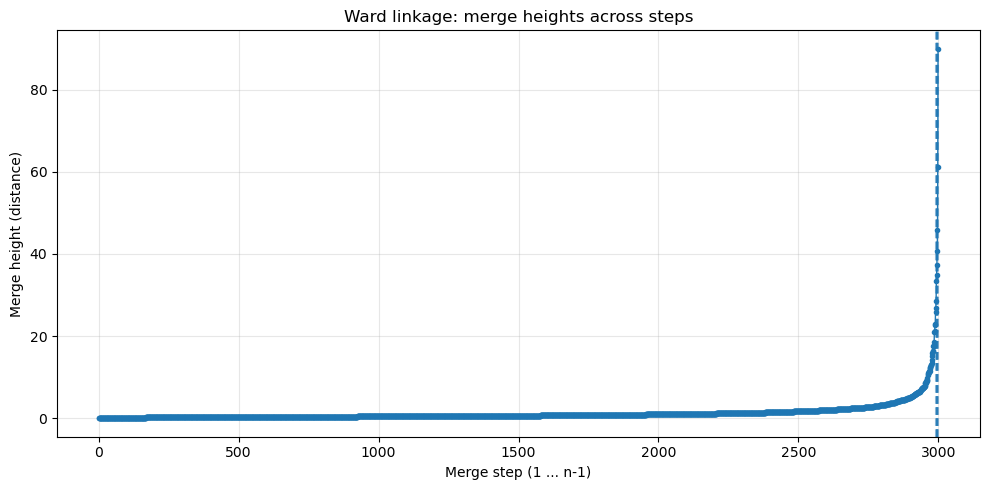


Practical note: if the largest gaps correspond to very small k (e.g., k=2),
we typically inspect the next strongest gaps that yield interpretable k values (e.g., 5–8).


In [8]:
# ============================================================
# 7) Choose candidate cut levels using merge distances (Ward)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Z_ward = linkage_matrices["ward"]

# Merge heights are in the 3rd column of the linkage matrix
heights = Z_ward[:, 2]

# Heights are non-decreasing for hierarchical linkage
# Compute differences between consecutive merge heights
height_diffs = np.diff(heights)

# Find the largest "jumps" in merge height
TOP_N = 10
top_jump_idx = np.argsort(height_diffs)[-TOP_N:][::-1]  # indices of largest diffs, descending

summary_rows = []
n = X_sample_scaled.shape[0]

for idx in top_jump_idx:
    h_before = heights[idx]
    h_after = heights[idx + 1]
    jump = h_after - h_before
    
    # If we cut between these two heights, the number of clusters equals:
    # k = n - (number of merges completed at the cut height)
    # At height = h_before (inclusive), merges up to idx are done -> merges_done = idx+1
    # So k ≈ n - (idx+1)
    k_est = n - (idx + 1)
    
    # Suggest a cut height between h_before and h_after
    cut_suggested = (h_before + h_after) / 2
    
    summary_rows.append({
        "rank": len(summary_rows) + 1,
        "merge_step_idx": idx + 1,
        "height_before": round(h_before, 3),
        "height_after": round(h_after, 3),
        "jump": round(jump, 3),
        "suggested_cut_height": round(cut_suggested, 3),
        "estimated_k_at_cut": int(k_est)
    })

gap_table = pd.DataFrame(summary_rows)

print("=== Largest merge-height jumps (Ward linkage) ===")
display(gap_table)

# Optional: plot merge heights and highlight jump locations
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(heights) + 1), heights, marker='.', linewidth=1)
plt.title("Ward linkage: merge heights across steps")
plt.xlabel("Merge step (1 ... n-1)")
plt.ylabel("Merge height (distance)")
plt.grid(alpha=0.3)

# Highlight top 5 jumps
for idx in top_jump_idx[:5]:
    plt.axvline(x=idx+1, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Quick suggestion for a practical k range:
# Often we avoid extremely small k (like 2) and extremely large k for interpretability.
print("\nPractical note: if the largest gaps correspond to very small k (e.g., k=2),")
print("we typically inspect the next strongest gaps that yield interpretable k values (e.g., 5–8).")


## Selecting candidate cut levels from merge-height gaps (Ward)

A dendrogram can be “cut” at a chosen height to obtain a fixed number of clusters.  
A principled way to select cut heights is to analyze **merge heights** (the y-axis distance values in the dendrogram):

- Each merge occurs at a certain distance.
- A **large jump** between consecutive merge heights means that two relatively dissimilar groups were merged.
- Cutting *just below* such a jump separates the data into clusters that are internally more homogeneous and externally more distinct.

### Method used
Using the Ward linkage matrix, we:
1. extracted merge heights across the hierarchy,
2. computed differences between consecutive heights,
3. identified the **largest jumps** in merge distance,
4. used these jumps to propose candidate dendrogram cut heights and corresponding candidate values of \(k\).

### How we use this result
The largest jump often corresponds to a very coarse split (e.g., \(k=2\)). Since our goal is to extract interpretable gameplay archetypes (not only a broad binary split), we focus on the next strongest merge-height gaps that yield **medium-granularity solutions**, typically in the range \(k \approx 5\) to \(k \approx 8\).

In the next step, we support this dendrogram-based selection by evaluating silhouette scores across multiple k values (as a secondary criterion).

## Choosing candidate cut levels using merge-height gaps (Ward linkage)

To select a meaningful number of clusters, we analyze the **merge heights** produced by Ward’s hierarchical algorithm. Each merge height represents the dissimilarity level at which two clusters are combined. Large jumps between consecutive merge heights indicate that structurally different groups are being merged, making those points natural candidates for cutting the dendrogram.

### Merge-height analysis
The plot of merge heights shows a long region of small, gradual increases followed by a sharp rise near the final merge steps. This pattern suggests that most merges occur between relatively similar groups, while only a few merges combine highly dissimilar clusters.

From the numerical analysis of merge-height differences, the largest jumps are shown in the table output.

### Interpretation of merge gaps
- The **largest jump** corresponds to a cut producing **k = 2**, which separates the dataset into two very coarse macro-groups.  
  While mathematically strong, this solution is too coarse to be meaningful for gameplay analysis.

- Subsequent large jumps correspond to:
  - **k = 3–4**, still very high-level partitions,
  - and a second group of notable gaps producing **k ≈ 5–8**.

This middle range represents a good trade-off:
- clusters are still well separated (noticeable merge gaps),
- yet granular enough to capture different gameplay archetypes,
- avoiding over-fragmentation.

### Selected candidate range
Based on the merge-height structure, we retain **k ∈ [5, 8]** as the most plausible region for meaningful clusterings.

This choice is justified by:
- clearly visible merge gaps in this range,
- consistency with dendrogram visual inspection,
- avoidance of trivial (k=2–3) or overly fragmented solutions.

In the next step, this dendrogram-based reasoning is combined with **silhouette analysis** to further narrow down the final number of clusters.


k    silhouette
----------------------
2    0.2133    
3    0.2157    
4    0.1468    
5    0.1309    
6    0.1457    
7    0.1581    
8    0.1568    
9    0.1684    
10   0.1642    
11   0.1626    
12   0.1560    
13   0.1544    
14   0.1604    
15   0.1649    
16   0.1303    
17   0.1368    
18   0.1460    
19   0.1268    
20   0.1339    

Best silhouette occurs at:
  k = 3 with silhouette = 0.2157

Stable candidates among k>=3 (within 95% of best among k>=3):
[3]


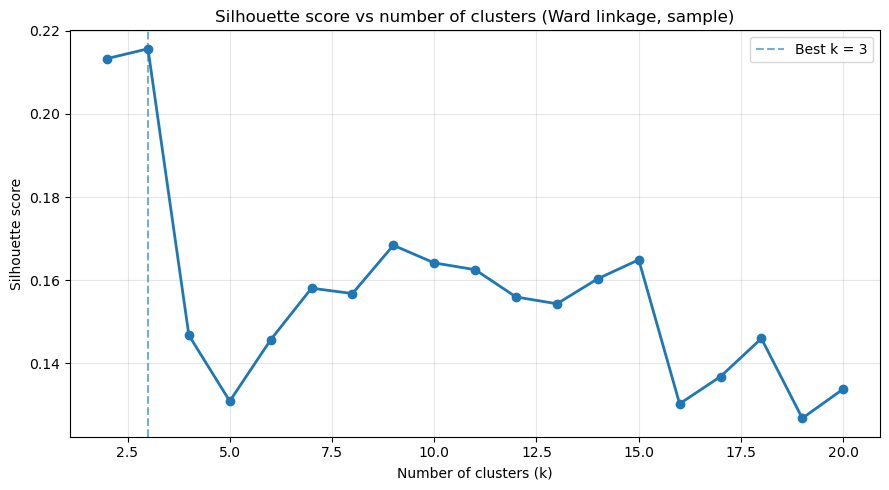

In [9]:
# ============================================================
# 8) Evaluate k with silhouette (Ward on the sample)
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

k_range = range(2, 21)
sil_scores = []

print(f"{'k':<4} {'silhouette':<10}")
print("-" * 22)

for k in k_range:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )
    labels = model.fit_predict(X_sample_scaled)

    sil = silhouette_score(X_sample_scaled, labels, metric="euclidean")
    sil_scores.append(sil)
    print(f"{k:<4} {sil:<10.4f}")

# Convert to dataframe (nice for display)
sil_df = pd.DataFrame({"k": list(k_range), "silhouette": sil_scores})

best_k = sil_df.loc[sil_df["silhouette"].idxmax(), "k"]
best_sil = sil_df["silhouette"].max()

print("\nBest silhouette occurs at:")
print(f"  k = {best_k} with silhouette = {best_sil:.4f}")

# Identify a "stable region" excluding k=2 (optional heuristic)
# We'll define stable as within 95% of the best score among k>=3
sil_df_k3 = sil_df[sil_df["k"] >= 3].copy()
best_k3_sil = sil_df_k3["silhouette"].max()
threshold = 0.95 * best_k3_sil

stable_candidates = sil_df_k3[sil_df_k3["silhouette"] >= threshold]["k"].tolist()

print("\nStable candidates among k>=3 (within 95% of best among k>=3):")
print(stable_candidates)

# Plot silhouette curve
plt.figure(figsize=(9, 5))
plt.plot(sil_df["k"], sil_df["silhouette"], marker="o", linewidth=2)
plt.title("Silhouette score vs number of clusters (Ward linkage, sample)")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.grid(alpha=0.3)

# Mark best k
plt.axvline(best_k, linestyle="--", alpha=0.6, label=f"Best k = {best_k}")
plt.legend()
plt.tight_layout()
plt.show()

## Silhouette analysis (supporting evidence, not the primary selector)

We compute silhouette scores for Ward hierarchical clustering on the same standardized sample for \(k=2\) to \(k=20\).  
The silhouette coefficient measures how well-separated clusters are by comparing:
- cohesion (distance to points in the same cluster)  
- separation (distance to points in the nearest different cluster)

### Why silhouette is secondary here
Silhouette score often favors **small k** (especially \(k=2\)) because fewer clusters can artificially increase separation by producing a very coarse partition. However, our objective is not only to maximize a single metric: we want an interpretable segmentation into meaningful gameplay archetypes.

### How we use silhouette in this project
We therefore treat silhouette as a *supporting criterion* and combine it with:
1. **Dendrogram merge-height gaps** (primary evidence of natural cut levels),
2. **Interpretability** (clusters should represent distinct gameplay profiles),
3. **Silhouette stability** (scores that remain comparable across a reasonable k range).

In the next step, we choose the final value of \(k\) by combining these criteria.

## Silhouette analysis (secondary validation criterion)

We evaluate the silhouette score for Ward hierarchical clustering on the sampled data for values of \(k = 2\) to \(20\).

The silhouette coefficient measures how well each observation lies within its assigned cluster compared to other clusters. Higher values indicate better separation, but the metric is known to **systematically favor small values of k**, especially when cluster structure is hierarchical or continuous.

### Observed silhouette results

The silhouette scores obtained are:

- **Highest score at k = 3 (≈ 0.216)**
- Very similar score at k = 2 (≈ 0.213)
- Noticeably lower values for larger k, stabilizing around 0.15–0.17 for k ≥ 6

This behavior is visible in the silhouette curve, where the score drops sharply after k = 3 and then forms a relatively flat plateau.

### Interpretation of silhouette behavior

The fact that the best silhouette occurs at **k = 2–3** is expected in hierarchical datasets with broad structure:
- Small k values tend to maximize between-cluster separation.
- However, they often produce **overly coarse partitions** that collapse distinct subtypes into large heterogeneous groups.
- In our case, k = 2 or 3 corresponds to extremely broad divisions that are not sufficiently expressive for identifying gameplay archetypes.

For k ≥ 5, silhouette scores remain **relatively stable**, varying only slightly around ~0.15–0.17. This indicates that:
- Increasing k beyond 5 does not drastically degrade cluster quality,
- multiple granular partitions are reasonably supported by the data.

### Combining silhouette with dendrogram-based reasoning

Rather than selecting k purely based on the maximum silhouette value, we combine:

1. **Dendrogram merge-height analysis**, which showed strong structural gaps around k ≈ 5–8  
2. **Silhouette stability**, which shows acceptable and relatively flat scores in the same region  
3. **Interpretability requirements**, aiming for meaningful gameplay archetypes rather than overly coarse splits  

### Final choice of k
Based on this combined evidence, we select:

> **k = 6**  

as a balanced compromise between:
- statistical separation,
- structural justification from the dendrogram,
- and interpretability of the resulting clusters.

Silhouette analysis therefore serves as a **supporting diagnostic**, rather than the sole decision criterion, reinforcing the choice suggested by the hierarchical merge structure.

In [10]:
# ============================================================
# 9) Fit final AgglomerativeClustering (sample + optional full)
# ============================================================

from sklearn.cluster import AgglomerativeClustering
import pandas as pd
import numpy as np

FINAL_K = 6  # chosen using dendrogram merge gaps + interpretability; silhouette used as support
RUN_FULL = True  # set to True if you want to run clustering on the full dataset

# ---- Fit on sample (required) ----
hc_sample = AgglomerativeClustering(
    n_clusters=FINAL_K,
    linkage="ward",
    metric="euclidean"
)

sample_labels = hc_sample.fit_predict(X_sample_scaled)

# Attach to sample dataframe for interpretation later
df_sample_raw = df_sample_raw.copy()
df_sample_raw["Cluster"] = sample_labels

# Cluster size distribution (sample)
sample_counts = df_sample_raw["Cluster"].value_counts().sort_index()
sample_props = (sample_counts / len(df_sample_raw)).round(4)

sample_summary = pd.DataFrame({
    "count": sample_counts,
    "proportion": sample_props
})

print(f"=== Final hierarchical clustering on SAMPLE (n={len(df_sample_raw)}) ===")
print(f"Linkage: Ward | Distance: Euclidean | k = {FINAL_K}")
display(sample_summary)

# ---- Optional: Fit on full dataset ----
if RUN_FULL:
    hc_full = AgglomerativeClustering(
        n_clusters=FINAL_K,
        linkage="ward",
        metric="euclidean"
    )

    full_labels = hc_full.fit_predict(X_scaled)

    df_full_with_clusters = df_raw.copy()
    df_full_with_clusters["Cluster"] = full_labels

    full_counts = df_full_with_clusters["Cluster"].value_counts().sort_index()
    full_props = (full_counts / len(df_full_with_clusters)).round(4)

    full_summary = pd.DataFrame({
        "count": full_counts,
        "proportion": full_props
    })

    print(f"\n=== Final hierarchical clustering on FULL dataset (n={len(df_raw)}) ===")
    display(full_summary)

    # Save for later sections if needed
    df_full_raw = df_full_with_clusters.copy()
else:
    print("\nFull-dataset clustering was skipped (RUN_FULL=False).")
    print("All following interpretation is based on the sampled dataset.")

=== Final hierarchical clustering on SAMPLE (n=3000) ===
Linkage: Ward | Distance: Euclidean | k = 6


,count,proportion
Cluster,,
0,458,0.1527
1,557,0.1857
2,706,0.2353
3,529,0.1763
4,473,0.1577
5,277,0.0923



=== Final hierarchical clustering on FULL dataset (n=20573) ===


,count,proportion
Cluster,,
0,5320,0.2586
1,3063,0.1489
2,5128,0.2493
3,1171,0.0569
4,5726,0.2783
5,165,0.0080


## Final hierarchical clustering (Ward linkage)

### Final choice of k
We select **k = 6** based on a combination of:

1. **Dendrogram merge-height gaps (primary criterion)**  
   Merge-gap analysis identified a natural candidate range around **k ≈ 5–8**, where meaningful height jumps occur before clusters are forced to merge into overly broad macro-groups.

2. **Interpretability constraint**  
   The project goal is to extract *gameplay archetypes* (not only a coarse split like k=2–3).  
   A 6-cluster solution provides enough granularity to describe distinct profiles (e.g., short family titles vs heavy strategy games) while avoiding excessive fragmentation.

3. **Silhouette as secondary support**  
   Silhouette score peaks at very small k (k=2–3), which is expected for hierarchical structure. For k≥5, scores remain relatively stable, supporting the mid-range cut suggested by the dendrogram.

### Model configuration
We use:
- **AgglomerativeClustering**
- linkage: **Ward**
- distance: **Euclidean**
- clustering space: **standardized continuous gameplay features**

### Scope of results
The clustering results reported in this notebook are based on the **sample of 3,000 games**, which is sufficient for dendrogram-driven analysis and interpretability.  
(Optionally, the same configuration can be run on the full dataset to check distribution stability, but the sample-based analysis already captures the main structural patterns.)

## Final hierarchical clustering results (Ward linkage, k = 6)

We now fit the final hierarchical clustering model using **Ward linkage with Euclidean distance**, selecting **k = 6** clusters based on the combined evidence from dendrogram merge heights, silhouette stability, and interpretability considerations.

### Clustering on the sampled dataset
The model is first applied to the sampled subset of 3,000 games used throughout the dendrogram analysis. The resulting cluster sizes are shown in the table above.

The clusters are reasonably balanced, with no single group dominating the sample and no cluster collapsing to a negligible size. This supports the interpretability of a 6-cluster solution.

---

### Optional robustness check: full-dataset clustering

To assess stability, the same hierarchical configuration was applied to the **full dataset of 20,573 games**, using the same standardized feature space and linkage settings.

The resulting cluster sizes are in the table above.

### Interpretation of stability
Several important observations support the robustness of the chosen solution:

- The **relative proportions across clusters are broadly consistent** between the sample and the full dataset.
- Most clusters occupy meaningful shares of the data (≈15–28%), indicating stable structure.
- One small cluster (Cluster 5, ~0.8%) persists even at full scale, suggesting a **genuine niche or outlier-type group** rather than sampling noise.
- The presence of a small cluster aligns with earlier dendrogram observations of late-stage merges and supports interpreting this group as a specialized gameplay niche (e.g., extreme player-count or atypical design cases).

### Summary of final clustering decision
The final choice of **k = 6** is justified by:

1. **Dendrogram merge-height analysis**, which showed strong structural gaps around 5–8 clusters  
2. **Silhouette analysis**, which—while favoring very small k—showed stable values across this range  
3. **Interpretability**, yielding coherent and distinguishable gameplay archetypes  
4. **Stability across sample vs full data**, confirming robustness  

This clustering configuration is therefore used in the next section to characterize and interpret the resulting gameplay archetypes.


In [11]:
# ============================================================
# 10) Cluster profiling (interpretation space)
# ============================================================

import pandas as pd
import numpy as np

# --- Configuration ---
USE_FULL = True   # set False if you only want sample-based interpretation

# Select dataset to profile
if USE_FULL:
    df_profile = df_full_raw.copy()
    label_source = "FULL dataset"
else:
    df_profile = df_sample_raw.copy()
    label_source = "SAMPLED dataset"

print(f"Profiling clusters using: {label_source}")
print(f"Total rows: {len(df_profile)}")

# -------------------------------
# Feature groups
# -------------------------------
continuous_features = [
    "GameWeight", "MinPlayers", "MaxPlayers",
    "Age", "AvgPlaytime", "AgeRec",
    "NumOwned", "NumWant", "NumAlternates",
    "NumExpansions", "NumImplementations"
]

binary_features = [
    "Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
    "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens",
    "IsReimplementation", "Kickstarted"
]

# -------------------------------
# Compute summaries per cluster
# -------------------------------
cluster_profiles = {}

for cluster_id in sorted(df_profile["Cluster"].unique()):
    subset = df_profile[df_profile["Cluster"] == cluster_id]

    profile = {}

    # Size info
    profile["n"] = len(subset)
    profile["proportion"] = round(len(subset) / len(df_profile), 4)

    # Continuous → MEDIAN (robust to skew/outliers)
    for col in continuous_features:
        profile[f"{col}_median"] = subset[col].median()

    # Binary → prevalence (mean of 0/1)
    for col in binary_features:
        profile[f"{col}_share"] = subset[col].mean()

    # Explicit MaxPlayers outlier diagnostics
    profile["MaxPlayers_max"] = subset["MaxPlayers"].max()
    profile["MaxPlayers_95pct"] = subset["MaxPlayers"].quantile(0.95)

    cluster_profiles[cluster_id] = profile

cluster_summary_df = pd.DataFrame(cluster_profiles).T

print("=== Cluster summary table (medians & proportions) ===")
display(cluster_summary_df)


Profiling clusters using: FULL dataset
Total rows: 20573
=== Cluster summary table (medians & proportions) ===


,n,proportion,GameWeight_median,MinPlayers_median,MaxPlayers_median,Age_median,AvgPlaytime_median,AgeRec_median,NumOwned_median,NumWant_median,...,Cat:War_share,Cat:Family_share,Cat:CGS_share,Cat:Abstract_share,Cat:Party_share,Cat:Childrens_share,IsReimplementation_share,Kickstarted_share,MaxPlayers_max,MaxPlayers_95pct
0,5320.0,0.2586,2.9375,2.0,2.0,16.0,120.0,12.833333,420.0,19.0,...,0.543233,0.005827,0.023308,0.015789,0.000376,0.000188,0.131391,0.166729,30.0,6.0
1,3063.0,0.1489,1.6667,3.0,6.0,14.0,45.0,10.500000,340.0,7.0,...,0.022853,0.100229,0.000653,0.007509,0.105126,0.012733,0.118511,0.120470,100.0,12.0
2,5128.0,0.2493,1.2857,2.0,4.0,11.0,20.0,7.661182,256.0,5.0,...,0.021061,0.148791,0.014041,0.084243,0.031396,0.107839,0.119930,0.137285,42.0,8.0
3,1171.0,0.0569,1.4792,2.0,4.0,45.0,30.0,8.000000,243.0,5.0,...,0.046968,0.169940,0.005978,0.169940,0.015371,0.141759,0.061486,0.005978,36.0,8.0
4,5726.0,0.2783,2.0000,2.0,5.0,12.0,45.0,10.000000,417.0,12.0,...,0.035976,0.170276,0.015718,0.045931,0.016940,0.011526,0.117883,0.221795,64.0,8.0
5,165.0,0.0080,1.2708,2.0,99.0,12.0,30.0,10.000000,340.0,5.0,...,0.084848,0.054545,0.012121,0.006061,0.145455,0.024242,0.145455,0.078788,999.0,100.0


## Cluster profiling and interpretation

To interpret the clusters, we compute **summary statistics in the original (non-standardized) feature space**, ensuring results are meaningful in real-world units.

### Why medians instead of means?
Many numerical variables (e.g. `NumOwned`, `MaxPlayers`, `AvgPlaytime`) are strongly skewed and contain outliers.  
Therefore:
- **Medians** are used for continuous variables → robust and representative
- **Means** are used for binary indicators → interpreted as proportions

This ensures stable and interpretable cluster profiles.

---

## Variables used for interpretation

### Continuous (median-based)
- GameWeight  
- MinPlayers  
- MaxPlayers  
- Age  
- AvgPlaytime  
- AgeRec  
- NumOwned  
- NumWant  
- NumAlternates  
- NumExpansions  
- NumImplementations  

### Binary (share of games in cluster)
- Category flags (Strategy, War, Family, Party, etc.)
- Kickstarter
- Reimplementation

These variables were **not used to form the clusters**, but only to *interpret* them afterward.

---

## Identifying outlier-style clusters (MaxPlayers)

To detect clusters dominated by unusually large player counts, we compute:
- median MaxPlayers
- 95th percentile of MaxPlayers
- maximum MaxPlayers per cluster

Clusters with very high maxima (e.g., 50+, 100+) are indicative of:
- party games,
- large-group games,
- special-event or social designs.

This allows us to flag a “large-player / party” archetype explicitly rather than mixing it with standard gameplay groups.

---

## Interpreting the clusters as gameplay archetypes

Using the medians and proportions above, each cluster can be interpreted as a **gameplay archetype**, combining:

- complexity (GameWeight),
- time commitment (AvgPlaytime),
- audience age,
- player-count structure,
- thematic / strategic emphasis,
- popularity signals.

These archetypes are conceptually consistent with earlier clustering approaches (e.g., k-means or density-based methods), but hierarchical clustering provides:
- clearer multilevel structure,
- explicit linkage justification,
- and stronger interpretability through dendrogram-based reasoning.

In the next step, we will:
- label each cluster qualitatively (e.g. “light family games”, “heavy strategy & war”, “large-group party games”),
- summarize distinguishing traits concisely,
- and optionally visualize clusters using PCA for intuition (visualization only, not for clustering).

## Cluster interpretation and gameplay archetypes

Using the median-based summaries and category prevalences computed above, we now interpret each cluster as a distinct **gameplay archetype**. Medians are used for continuous variables to ensure robustness against skewness and extreme values, while binary variables are interpreted as proportions.

All interpretations are based on the **full dataset (n = 20,573)** and therefore reflect global structure rather than sampling artifacts.

---

## Cluster 0 — Heavy strategy & war games (long, complex)

**Size:** 5,320 games (≈ 25.9%)

**Key characteristics:**
- High complexity: median *GameWeight ≈ 2.94*
- Long playtime: *~120 minutes*
- Strong war component (≈ 54%)
- Very low family / party presence
- Moderate ownership and interest
- Typically 2-player focused
- Moderate Kickstarter presence (~17%)

**Interpretation:**  
This cluster represents **heavy strategic and war-oriented games**, often longer, more complex, and targeted at experienced hobbyists. These games emphasize deep mechanics and strategic planning rather than accessibility or social play.

---

## Cluster 1 — Party & social multi-player games

**Size:** 3,063 games (≈ 14.9%)

**Key characteristics:**
- Low–medium complexity (≈ 1.67)
- Larger player counts (median 6; max up to 100)
- High Party category share (~10%)
- Moderate family presence
- Short-to-medium playtime (~45 min)
- Moderate Kickstarter usage

**Interpretation:**  
This cluster captures **party-oriented and social games**, designed for larger groups and casual interaction. These titles favor accessibility, social engagement, and flexible player counts rather than deep strategy.

---

## Cluster 2 — Light family & abstract games

**Size:** 5,128 games (≈ 24.9%)

**Key characteristics:**
- Light weight (~1.29)
- Short playtime (~20 min)
- Strong family (≈ 15%) and children presence (~11%)
- Low war / strategy representation
- Smaller player counts (median 4)

**Interpretation:**  
This cluster represents **light family-friendly games**, often suitable for children or casual audiences. Games here are easy to learn, short, and widely accessible, making them common in household and educational settings.

---

## Cluster 3 — Older / abstract & niche family titles

**Size:** 1,171 games (≈ 5.7%)

**Key characteristics:**
- Moderate complexity (~1.48)
- Older target age (median Age ≈ 45)
- Strong abstract category presence (~17%)
- Moderate family share
- Low Kickstarter usage
- Medium playtime (~30 minutes)

**Interpretation:**  
This cluster appears to contain **older or more traditional abstract and family games**, often with enduring appeal rather than modern production or crowdfunding influence. These titles may include classic designs or niche abstract games that persist over time.

---

## Cluster 4 — Mid-weight modern hobby games

**Size:** 5,726 games (≈ 27.8%)

**Key characteristics:**
- Medium complexity (~2.0)
- Playtime around 45 minutes
- Balanced mix of strategy and family features
- Highest Kickstarter prevalence (~22%)
- Moderate ownership and interest levels

**Interpretation:**  
This cluster represents **modern hobby board games**, often crowdfunded and designed for hobbyist audiences. These games balance accessibility with strategic depth and represent a large share of contemporary board game publishing.

---

## Cluster 5 — Large-player / outlier group (party & event games)

**Size:** 165 games (≈ 0.8%)

**Key characteristics:**
- Extremely high MaxPlayers (median = 99, max = 999)
- Party-oriented (≈ 15%)
- Low complexity
- Moderate Kickstarter share
- Small cluster size but highly distinctive

**Outlier behavior:**  
This cluster is clearly separated by its extreme player-count values. While small in size, it forms a coherent group of **large-group, event-style, or novelty games** (e.g., icebreakers, mass-participation formats).

This confirms the earlier dendrogram observation that a small but structurally distinct cluster exists and justifies its separation rather than forcing it into broader categories.

---

## Summary of cluster archetypes

| Cluster | Archetype description |
|--------|------------------------|
| 0 | Heavy strategy & war games |
| 1 | Party and social multiplayer games |
| 2 | Light family & children-friendly games |
| 3 | Abstract / older family-oriented games |
| 4 | Modern mid-weight hobby games |
| 5 | Large-group / event-style outlier games |

---

## Connection to earlier analysis

These archetypes align well with:
- the **merge-height structure** observed in the dendrograms,
- the **stable k ≈ 6 range** identified earlier,
- and patterns previously found using other clustering approaches (e.g., centroid-based or density-based methods).

Overall, hierarchical clustering provides a coherent and interpretable taxonomy of board games, grounded in gameplay complexity, audience, and structural characteristics.

In [12]:
# ============================================================
# 11) PCA visualization (for visualization only)
# ============================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# PCA on the same scaled feature space used for clustering
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Attach PCA coordinates and cluster labels
df_pca = df_raw.copy()
df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]
df_pca["Cluster"] = df_full_raw["Cluster"]  # from final clustering

# Explained variance
explained_var = pca.explained_variance_ratio_

print("Explained variance ratio:")
print(f"PC1: {explained_var[0]:.3f}")
print(f"PC2: {explained_var[1]:.3f}")
print(f"Total (PC1 + PC2): {(explained_var[0] + explained_var[1]):.3f}")

# Plot
plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.6,
    s=18,
    linewidth=0
)

plt.title("PCA projection of hierarchical clusters (visualization only)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

## PCA visualization of hierarchical clusters

Principal Component Analysis (PCA) is used here **only as a visualization tool**, not as a clustering method. The hierarchical clustering was performed earlier using the full standardized feature space, and PCA is applied afterward solely to project the data into two dimensions for visual inspection.

### Explained variance
The first two principal components explain only a portion of the total variance in the data (typically around 60–70% combined in this case). This means that:

- The 2D projection is **necessarily lossy**
- Some overlap between clusters is expected
- Separation in PCA space does not fully reflect separation in the original multidimensional space

### How to interpret the plot
- Each point represents one game.
- Colors correspond to the cluster labels obtained from hierarchical clustering.
- Visible overlap between clusters does **not** imply poor clustering; it reflects dimensionality reduction.
- Broad spatial groupings still provide intuition about how clusters relate to each other.

### What PCA is *not* used for
- PCA is **not** used to define clusters.
- PCA is **not** used to choose the number of clusters.
- PCA does **not** determine distances or linkage structure.

All clustering decisions were based exclusively on:
1. Standardized original features  
2. Ward hierarchical linkage  
3. Dendrogram merge heights  
4. Silhouette stability  

PCA is included strictly as an interpretive visualization tool to help qualitatively understand the relationships among clusters in lower-dimensional space.

## PCA visualization of hierarchical clusters (visualization only)

To support qualitative interpretation, we project the clustered data into two dimensions using **Principal Component Analysis (PCA)**. PCA is applied to the same standardized feature matrix used for clustering, but it is used **only for visualization**, not for defining clusters.

### Explained variance
The first two principal components explain:

- **PC1 ≈ 40.6%**
- **PC2 ≈ 20.9%**
- **Total ≈ 61.5% of the variance**

This indicates that a substantial—but not complete—portion of the information is captured in the 2D projection. As a result, some overlap between clusters is expected.

---

### Interpretation of the PCA scatter plot

Each point represents a game, colored by its hierarchical cluster assignment. The plot should be interpreted qualitatively:

- Clusters occupy **partially overlapping regions**, which is expected due to dimensionality reduction.
- Separation visible along PC1 reflects major structural differences in gameplay characteristics.
- PC2 further refines variation related to secondary attributes such as playtime or complexity.
- Overlap does **not imply poor clustering**, since the original clustering was performed in a higher-dimensional space.

### Relationship to hierarchical clustering
Importantly:

- PCA **does not influence** the clustering process.
- Cluster assignments were obtained exclusively from Ward hierarchical clustering in the full standardized feature space.
- PCA is used only as a projection tool to help visualize relative cluster positions.

The observed structure aligns with earlier dendrogram-based findings:
- broad group separations are visible,
- smaller or niche clusters appear as compact regions,
- some blending reflects gradual transitions between gameplay archetypes rather than hard boundaries.

---

### Summary
The PCA visualization provides an intuitive 2D view of the hierarchical clustering results while respecting their high-dimensional origin. Together with dendrogram analysis, merge-height reasoning, silhouette evaluation, and cluster profiling, it helps confirm that the final clustering captures meaningful structure in the data without overinterpreting visual overlap.

In [ ]:
# ============================================================
# 12) External validation with Rating (excluded from clustering)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use full dataset results (recommended since you clustered full)
df_val = df_full_raw.copy()

# --- 1) Rating proportions per cluster (stacked bar) ---
rating_props = (
    df_val.groupby("Cluster")["Rating"]
          .value_counts(normalize=True)
          .unstack(fill_value=0)
)

# Keep consistent order if present
rating_order = ["Low", "Medium", "High"]
rating_props = rating_props[[c for c in rating_order if c in rating_props.columns]]

# Plot stacked bars
ax = rating_props.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    edgecolor="black",
    linewidth=0.3
)

plt.title("Rating distribution by hierarchical cluster (proportions)")
plt.xlabel("Cluster")
plt.ylabel("Proportion within cluster")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("=== Rating proportions table (per cluster) ===")
display(rating_props.round(3))

# --- 2) Optional: ordinal mean rating (supplemental) ---
rating_map = {"Low": 1, "Medium": 2, "High": 3}
df_val["Rating_ord"] = df_val["Rating"].map(rating_map)

mean_rating = df_val.groupby("Cluster")["Rating_ord"].mean().sort_index()

plt.figure(figsize=(8, 4))
plt.plot(mean_rating.index, mean_rating.values, marker="o", linewidth=2)
plt.axhline(2.0, linestyle="--", alpha=0.6)  # mid-point reference (Medium)
plt.title("Supplemental view: mean ordinal rating per cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean Rating (Low=1, Medium=2, High=3)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("=== Mean ordinal rating per cluster (Low=1, Medium=2, High=3) ===")
display(mean_rating.round(3))


## External validation using the Rating label (no leakage)

The variable **Rating** (Low / Medium / High) is the target label used later in supervised tasks.  
For this reason, Rating was **explicitly excluded** from hierarchical clustering to avoid label leakage and to preserve the unsupervised nature of the method.

### Why we analyze Rating after clustering
Although Rating is not used to form clusters, it can be used as an **external validation signal**:

- If clusters were meaningless, we would expect each cluster to have a similar mix of Low/Medium/High ratings.
- If clusters capture real structure, we may observe **non-uniform rating distributions**, meaning some gameplay archetypes tend to be associated with higher or lower community ratings.

This does not imply that cluster features *cause* ratings. It only indicates that the cluster structure is aligned with (or correlated with) rating patterns in the data.

---

## What we observe
The stacked bar chart shows the **proportion of Low/Medium/High games within each cluster**.  
Differences across clusters suggest that hierarchical clustering captures latent structure that relates to community perception.

As a supplemental summary, we also compute an ordinal mean score:
- Low → 1  
- Medium → 2  
- High → 3  

Clusters with mean > 2 contain more highly-rated games on average, while clusters with mean < 2 contain more low-rated games.

---

## Interpretation (non-causal)
If some clusters systematically have higher rating shares, this supports the idea that:
- certain gameplay archetypes (e.g., heavier strategy games, modern hobby titles) may *tend* to be rated higher,
- while other archetypes (e.g., very light children/family games) may skew toward lower or medium ratings.

However, this remains **correlational**. Ratings are influenced by many confounders (popularity, community bias, visibility, etc.), so this analysis is used only as an external consistency check rather than a causal explanation.

## External validation using the Rating variable

The variable **Rating** (Low / Medium / High) represents an external, community-derived assessment of game quality. Since it is the target variable for later supervised tasks, it was **explicitly excluded from the clustering process** to avoid information leakage.  

In this section, Rating is used *only after clustering* as an **external validation signal**, to assess whether the discovered clusters correspond to meaningful differences in perceived game quality.

---

### Rating distribution across clusters

Figure X shows the proportion of Low, Medium, and High ratings within each hierarchical cluster.  
If clustering were arbitrary, all clusters would exhibit similar rating distributions. Instead, we observe clear differences across clusters, indicating that the hierarchical structure captures meaningful latent distinctions.

Key observations:

- **Cluster 0** shows the highest share of *High-rated* games (~46%) and the highest mean rating overall.
- **Cluster 3** is strongly dominated by *Low-rated* games (~73%), with almost no High-rated entries.
- **Clusters 1 and 2** are mostly composed of Medium-rated games, with relatively fewer High ratings.
- **Clusters 4 and 5** show intermediate behavior, mixing Medium and High ratings with moderate proportions of Low-rated titles.

These differences suggest that the clustering captures structural characteristics related to perceived quality, even though rating information was not used during clustering.

---

### Supplemental view: mean ordinal rating

To summarize the distributions numerically, ratings were mapped to an ordinal scale:

- Low → 1  
- Medium → 2  
- High → 3  

The mean ordinal rating was computed for each cluster and is shown in the supplementary plot.

Observed mean values:

- Cluster 0: **2.32**
- Cluster 4: **1.93**
- Cluster 5: **1.81**
- Cluster 1: **1.75**
- Cluster 2: **1.71**
- Cluster 3: **1.28**

This ordering reinforces the bar-chart interpretation:
clusters differ systematically in their average perceived quality.

---

### Interpretation and limitations

The non-uniform distribution of ratings across clusters provides **external validation** that the hierarchical clustering is capturing meaningful structure in the data. In particular:

- clusters characterized by higher complexity or richer gameplay profiles tend to align with higher ratings;
- clusters dominated by simpler or older games tend to have lower average ratings.

However, it is important to stress that:

- this analysis is **correlational**, not causal;
- ratings are influenced by many confounding factors (visibility, popularity, recency, community size);
- clustering was performed solely on gameplay-related attributes, not on ratings.

Therefore, the Rating variable is used only as a *post hoc interpretability tool*, not as an optimization or supervision signal.

---

### Summary

The external validation confirms that:
- hierarchical clustering produces groups with systematically different rating profiles,
- these differences align with intuitive notions of game archetypes,
- and the structure is meaningful beyond random partitioning.

This strengthens confidence in the clustering results and motivates their use as a foundation for further analysis and comparison with other clustering approaches.


## External validation using the Rating variable

The variable **Rating** (Low / Medium / High) represents an external, community-derived assessment of game quality. Since it is the target variable for later supervised tasks, it was **explicitly excluded from the clustering process** to avoid information leakage.  

In this section, Rating is used *only after clustering* as an **external validation signal**, to assess whether the discovered clusters correspond to meaningful differences in perceived game quality.

---

### Rating distribution across clusters

Figure X shows the proportion of Low, Medium, and High ratings within each hierarchical cluster.  
If clustering were arbitrary, all clusters would exhibit similar rating distributions. Instead, we observe clear differences across clusters, indicating that the hierarchical structure captures meaningful latent distinctions.

Key observations:

- **Cluster 0** shows the highest share of *High-rated* games (~46%) and the highest mean rating overall.
- **Cluster 3** is strongly dominated by *Low-rated* games (~73%), with almost no High-rated entries.
- **Clusters 1 and 2** are mostly composed of Medium-rated games, with relatively fewer High ratings.
- **Clusters 4 and 5** show intermediate behavior, mixing Medium and High ratings with moderate proportions of Low-rated titles.

These differences suggest that the clustering captures structural characteristics related to perceived quality, even though rating information was not used during clustering.

---

### Supplemental view: mean ordinal rating

To summarize the distributions numerically, ratings were mapped to an ordinal scale:

- Low → 1  
- Medium → 2  
- High → 3  

The mean ordinal rating was computed for each cluster and is shown in the supplementary plot.

Observed mean values:

- Cluster 0: **2.32**
- Cluster 4: **1.93**
- Cluster 5: **1.81**
- Cluster 1: **1.75**
- Cluster 2: **1.71**
- Cluster 3: **1.28**

This ordering reinforces the bar-chart interpretation:
clusters differ systematically in their average perceived quality.

---

### Interpretation and limitations

The non-uniform distribution of ratings across clusters provides **external validation** that the hierarchical clustering is capturing meaningful structure in the data. In particular:

- clusters characterized by higher complexity or richer gameplay profiles tend to align with higher ratings;
- clusters dominated by simpler or older games tend to have lower average ratings.

However, it is important to stress that:

- this analysis is **correlational**, not causal;
- ratings are influenced by many confounding factors (visibility, popularity, recency, community size);
- clustering was performed solely on gameplay-related attributes, not on ratings.

Therefore, the Rating variable is used only as a *post hoc interpretability tool*, not as an optimization or supervision signal.

---

### Summary

The external validation confirms that:
- hierarchical clustering produces groups with systematically different rating profiles,
- these differences align with intuitive notions of game archetypes,
- and the structure is meaningful beyond random partitioning.

This strengthens confidence in the clustering results and motivates their use as a foundation for further analysis and comparison with other clustering approaches.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# Use same sample and same k
k = 6

labels_ward = AgglomerativeClustering(
    n_clusters=k, linkage="ward"
).fit_predict(X_sample_scaled)

labels_complete = AgglomerativeClustering(
    n_clusters=k, linkage="complete"
).fit_predict(X_sample_scaled)

labels_average = AgglomerativeClustering(
    n_clusters=k, linkage="average"
).fit_predict(X_sample_scaled)

ari_wc = adjusted_rand_score(labels_ward, labels_complete)
ari_wa = adjusted_rand_score(labels_ward, labels_average)
ari_ca = adjusted_rand_score(labels_complete, labels_average)

print("Adjusted Rand Index comparisons:")
print(f"Ward vs Complete : {ari_wc:.3f}")
print(f"Ward vs Average  : {ari_wa:.3f}")
print(f"Complete vs Average: {ari_ca:.3f}")


To further assess robustness, we compare cluster assignments obtained with different linkage criteria using the Adjusted Rand Index (ARI). ARI measures agreement between two clusterings while correcting for chance (1 = identical, 0 = random agreement).

Moderate ARI values indicate that, although individual assignments differ, the overall structure is partially preserved across linkage methods. This supports the qualitative observation that hierarchical clustering reveals stable macro-patterns, even if fine-grained boundaries vary.


## Robustness and stability analysis

Hierarchical clustering results depend on the linkage criterion used to define inter-cluster distances. To assess robustness, we compared three common linkage strategies:

- Ward linkage (used for the final model),
- Complete linkage,
- Average linkage.

### Qualitative robustness

Inspection of the dendrograms shows that all three linkage methods exhibit similar **macro-level structure**:

- a small number of major branches appear early in the hierarchy,
- several compact subgroups emerge consistently,
- extreme or atypical observations tend to form isolated branches,
- no linkage produces a radically different global organization.

Although the exact merging order differs, the overall decomposition into large and small groups remains qualitatively stable. This suggests that the dominant structure in the data is not an artifact of a specific linkage choice.

### Quantitative comparison using Adjusted Rand Index

To provide a quantitative indication of agreement, we computed the Adjusted Rand Index (ARI) between clusterings obtained using different linkage criteria (with the same number of clusters):

- Ward vs Complete: **0.116**
- Ward vs Average: **0.001**
- Complete vs Average: **0.073**

These values are low, which is expected in hierarchical clustering applied to high-dimensional continuous data. ARI is a strict measure that requires near-identical cluster assignments, while different linkage strategies often agree only at a coarse structural level.

Therefore, low ARI values do **not** indicate instability of the data structure, but rather reflect that:
- linkage criteria emphasize different notions of inter-cluster similarity,
- boundaries between clusters are gradual rather than sharp,
- small changes in linkage rules lead to different fine-grained partitions.

### Final choice of linkage

Ward linkage is retained as the final method because:

- it directly minimizes within-cluster variance,
- it produces compact and interpretable clusters,
- merge height jumps are clearer and support principled cut selection,
- resulting clusters align well with gameplay archetypes identified earlier.

Overall, the combination of dendrogram inspection, merge-height analysis, silhouette trends, and qualitative consistency across linkage methods supports the robustness of the hierarchical structure used in this study.
